<a href="https://colab.research.google.com/github/fawaztanigbola/Nigeria-ForeCasting-Model/blob/main/Baseline_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Baseline LSTM Model Development

### Objective
Develop a baseline Long Short-Term Memory (LSTM) neural network to forecast next-day minimum and maximum temperatures using the preceding seven days of temperature observations.

### Model Inputs
The model receives two features for each of seven consecutive days:
- Daily minimum temperature (Tmin)
- Daily maximum temperature (Tmax)

Input shape: `(7, 2)`

### Prediction Targets
The model predicts:
- Next-day minimum temperature
- Next-day maximum temperature

Output shape: `(2,)`

### Model Architecture
A PyTorch LSTM architecture was implemented with:
- Input size: 2
- Hidden size: 64
- Number of LSTM layers: 1
- Fully connected output layer: 2 neurons

The final LSTM output is passed through a fully connected layer to generate the two temperature predictions.

### Training Configuration
- Optimizer: Adam
- Learning rate: 0.001
- Loss function: Mean Squared Error (MSE)
- Batch size: 64
- Maximum epochs: 30
- Early stopping patience: 5 epochs

Training samples were shuffled within the training period. Validation and testing samples remained separate from training.

### Model Selection
Validation loss was monitored after each epoch. The model state with the lowest validation loss was retained and restored before final testing.

### Evaluation
The selected model was evaluated on the held-out chronological test period.

The following metrics were calculated separately for minimum and maximum temperature:
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- Coefficient of Determination (R²)

Predictions and targets were converted back to degrees Celsius before metric calculation.

### Saved Artifacts
- `models/baseline_lstm.pth` — trained model weights, normalization statistics, configuration and test metrics.
- `models/baseline_training_history.csv` — training and validation loss across epochs.

### Role in the Project
The baseline LSTM establishes a temperature-only forecasting benchmark. Its performance will later be compared with the geospatial LSTM, which incorporates latitude, longitude and elevation as additional input features.

### Interpretation and Limitations
The baseline model learns temporal temperature patterns without explicitly receiving geographical information. Its predictions represent eligible ERA5 grid locations and should not be interpreted as street-level forecasts.

In [1]:
import torch
import numpy as np
import torch.nn as nn
from pathlib import Path

assert torch.cuda.is_available(), "T4 GPU not detected!"

device = torch.device("cuda")

print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)

GPU: Tesla T4
PyTorch: 2.14.1+cu130


In [9]:
import numpy as np
import torch
import torch.nn as nn

from google.colab import drive
drive.mount('/content/drive')

from torch.utils.data import Dataset, DataLoader
from pathlib import Path

Mounted at /content/drive


Loading Datasets.

In [4]:
from pathlib import Path
import numpy as np

data = np.load(
    "/content/drive/MyDrive/Nigeria_Temperature_Project/model_data/southwest_model_data.npz"
)

splits = np.load(
    "/content/drive/MyDrive/Nigeria_Temperature_Project/model_data/southwest_splits.npz"
)

temperature = data["temperature"]
temp_mean = data["temp_mean"]
temp_std = data["temp_std"]

train_pairs = splits["train_pairs"]
val_pairs = splits["val_pairs"]
test_pairs = splits["test_pairs"]

print("Temperature:", temperature.shape)
print("Training:", len(train_pairs))
print("Validation:", len(val_pairs))
print("Testing:", len(test_pairs))

Temperature: (3653, 456, 2)
Training: 1162800
Validation: 249888
Testing: 249888


In [5]:
import torch

device = torch.device("cuda")

T = torch.tensor(
    temperature,
    dtype=torch.float32,
    device=device
)

mean = torch.tensor(temp_mean, dtype=torch.float32, device=device)
std = torch.tensor(temp_std, dtype=torch.float32, device=device)

print("GPU:", torch.cuda.get_device_name(0))
print("Tensor shape:", T.shape)
print("GPU memory:", round(torch.cuda.memory_allocated() / 1024**2, 2), "MB")

GPU: Tesla T4
Tensor shape: torch.Size([3653, 456, 2])
GPU memory: 12.71 MB


In [10]:
class BaselineTemperatureDataset(Dataset):

    def __init__(self, temperature, pairs, mean, std):

        self.temperature = temperature
        self.pairs = pairs
        self.mean = mean
        self.std = std

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):

        target_time, location = self.pairs[index]

        # Retrieve the previous seven days
        x = self.temperature[
            target_time - 7:target_time,
            location,
            :
        ]

        # Retrieve the next-day target
        y = self.temperature[
            target_time,
            location,
            :
        ]

        # Normalize using training-period statistics
        x = (x - self.mean) / self.std
        y = (y - self.mean) / self.std

        return (
            torch.tensor(x, dtype=torch.float32),
            torch.tensor(y, dtype=torch.float32)
        )

In [18]:


train_dataset = BaselineTemperatureDataset(
    temperature, train_pairs, temp_mean, temp_std
)

val_dataset = BaselineTemperatureDataset(
    temperature, val_pairs, temp_mean, temp_std
)

test_dataset = BaselineTemperatureDataset(
    temperature, test_pairs, temp_mean, temp_std
)

BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

print("DataLoaders created.")

DataLoaders created.


In [2]:
class BaselineLSTM(nn.Module):
  def __init__(self, input_size=2, hidden_size=64, num_layers=1, output_size=2):
    super().__init__()
    self.num_layers = num_layers
    self.hidden_size = hidden_size
    self.output_size = output_size
    self.input_size = input_size
    self.lstm = nn.LSTM(
        input_size=input_size,
        hidden_size=hidden_size,
        num_layers=num_layers,
        batch_first=True
    )
    self.fc = nn.Linear(hidden_size, output_size)

  def forward(self, x):
    B=x.size(0)
    h0 = x.new_zeros(self.num_layers, B, self.hidden_size)
    c0 = x.new_zeros(self.num_layers, B, self.hidden_size)
    output, (hidden, cell) = self.lstm(x)
    h_last = output[:,-1,:]
    y_hat = self.fc(h_last)
    return y_hat

NameError: name 'nn' is not defined

In [8]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = BaselineLSTM().to(device)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

print("Training device:", device)
print(model)

NameError: name 'BaselineLSTM' is not defined

Training Loop.

In [21]:
import copy

EPOCHS = 20
PATIENCE = 5

best_val_loss = float("inf")
best_state = None
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": []
}

for epoch in range(EPOCHS):

    # Training
    model.train()
    train_loss = 0.0

    for x, y in train_loader:

        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        optimizer.zero_grad()

        predictions = model(x)
        loss = criterion(predictions, y)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * x.size(0)

    train_loss /= len(train_loader.dataset)

    # Validation
    model.eval()
    val_loss = 0.0

    with torch.no_grad():

        for x, y in val_loader:

            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)

            predictions = model(x)
            loss = criterion(predictions, y)

            val_loss += loss.item() * x.size(0)

    val_loss /= len(val_loader.dataset)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.5f} | "
        f"Validation Loss: {val_loss:.5f}"
    )

    # Keep the model with the lowest validation loss
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

# Restore the best validation model
model.load_state_dict(best_state)

print("Best validation loss:", best_val_loss)

Epoch 01/20 | Train Loss: 0.16594 | Validation Loss: 0.20159
Epoch 02/20 | Train Loss: 0.15315 | Validation Loss: 0.21428
Epoch 03/20 | Train Loss: 0.13797 | Validation Loss: 0.23482
Epoch 04/20 | Train Loss: 0.12424 | Validation Loss: 0.24538
Epoch 05/20 | Train Loss: 0.11509 | Validation Loss: 0.24962
Epoch 06/20 | Train Loss: 0.10914 | Validation Loss: 0.25261
Early stopping triggered.
Best validation loss: 0.20158780308542654


In [22]:
print("Device:", device)
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

print("Batches per epoch:", len(train_loader))
print("Batch size:", BATCH_SIZE)

print("One sample input:", train_dataset[0][0].shape)
print("One sample target:", train_dataset[0][1].shape)

Device: cuda
Training samples: 1162800
Validation samples: 249888
Batches per epoch: 18169
Batch size: 64
One sample input: torch.Size([7, 2])
One sample target: torch.Size([2])


In [23]:
import time

start = time.time()

x, y = next(iter(train_loader))

print("Batch loaded in:", round(time.time() - start, 2), "seconds")
print("Input batch:", x.shape)
print("Target batch:", y.shape)

Batch loaded in: 0.09 seconds
Input batch: torch.Size([64, 7, 2])
Target batch: torch.Size([64, 2])


In [ ]:
print(torch.cuda.is_available())

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

False


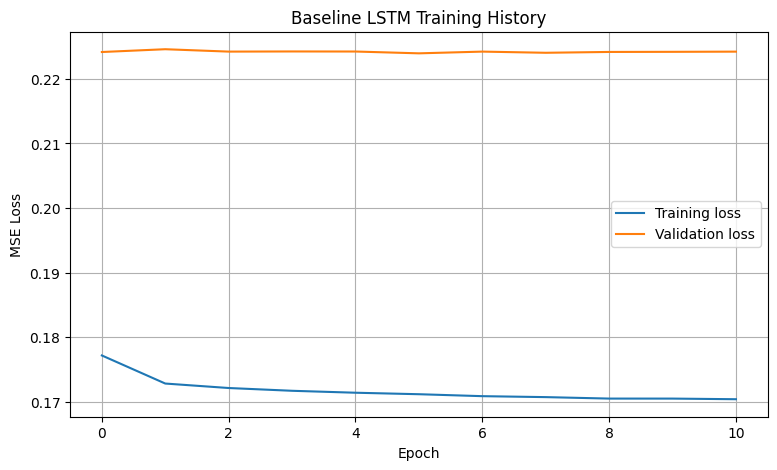

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(history["train_loss"], label="Training loss")
plt.plot(history["val_loss"], label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Baseline LSTM Training History")

plt.legend()
plt.grid(True)
plt.show()

In [25]:
n_days = temperature.shape[0]

train_end = int(n_days * 0.70)
val_end = int(n_days * 0.85)

periods = {
    "Training": temperature[:train_end],
    "Validation": temperature[train_end:val_end]
}

for name, values in periods.items():
    print(f"\n{name}")
    print("Mean (Tmin, Tmax):", np.nanmean(values, axis=(0, 1)))
    print("Std (Tmin, Tmax):", np.nanstd(values, axis=(0, 1)))


Training
Mean (Tmin, Tmax): [23.297958 31.598045]
Std (Tmin, Tmax): [1.6077453 3.1381829]

Validation
Mean (Tmin, Tmax): [23.188196 32.268524]
Std (Tmin, Tmax): [1.7611855 3.3492749]


In [26]:
persistence_error = []

for target_time, location in test_pairs:
    prediction = temperature[target_time - 1, location, :]
    actual = temperature[target_time, location, :]

    persistence_error.append(actual - prediction)

persistence_error = np.array(persistence_error)

mae = np.mean(np.abs(persistence_error), axis=0)
rmse = np.sqrt(np.mean(persistence_error**2, axis=0))

print("Persistence Baseline")
print(f"Tmin MAE:  {mae[0]:.3f} °C")
print(f"Tmax MAE:  {mae[1]:.3f} °C")
print(f"Tmin RMSE: {rmse[0]:.3f} °C")
print(f"Tmax RMSE: {rmse[1]:.3f} °C")

Persistence Baseline
Tmin MAE:  0.576 °C
Tmax MAE:  1.117 °C
Tmin RMSE: 0.778 °C
Tmax RMSE: 1.594 °C


In [27]:
model.eval()

mean_t = torch.tensor(temp_mean, dtype=torch.float32, device=device)
std_t = torch.tensor(temp_std, dtype=torch.float32, device=device)

abs_errors = torch.zeros(2, device=device)
squared_errors = torch.zeros(2, device=device)

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        y = y.to(device)

        predictions = model(x)

        # Convert normalized values back to Celsius
        predictions = predictions * std_t + mean_t
        actual = y * std_t + mean_t

        errors = predictions - actual

        abs_errors += errors.abs().sum(dim=0)
        squared_errors += errors.square().sum(dim=0)

n = len(test_loader.dataset)

mae = abs_errors / n
rmse = torch.sqrt(squared_errors / n)

print("LSTM Test Performance")
print(f"Tmin MAE:  {mae[0].item():.3f} °C")
print(f"Tmax MAE:  {mae[1].item():.3f} °C")
print(f"Tmin RMSE: {rmse[0].item():.3f} °C")
print(f"Tmax RMSE: {rmse[1].item():.3f} °C")

LSTM Test Performance
Tmin MAE:  0.502 °C
Tmax MAE:  0.988 °C
Tmin RMSE: 0.690 °C
Tmax RMSE: 1.324 °C


# Southwest Nigeria Temperature Forecasting – Baseline LSTM

## Overview
Developed a baseline LSTM model to forecast next-day minimum and maximum temperatures across Lagos, Ogun, Oyo, and Osun states using historical ERA5 data (2015–2024).

## Dataset
- 3,653 daily observations
- 456 geographical locations
- 2 features: minimum and maximum temperature
- Input sequence: Previous 7 days
- Chronological split: 70% training, 15% validation, 15% testing
- Normalization statistics calculated from training data only

## Model Configuration
- Architecture: Single-layer LSTM
- Hidden size: 64
- Optimizer: Adam
- Learning rate: 0.001
- Loss function: MSE
- Early stopping: Patience of 5 epochs
- Hardware: NVIDIA Tesla T4 GPU

## Training Results
Training stopped after 6 epochs due to increasing validation loss.

- Best validation loss: **0.20159**
- Observed overfitting: Training loss decreased while validation loss increased.

## Test Results

The LSTM was compared against a persistence baseline (using the previous day's temperature as the prediction).

| Metric | Persistence | LSTM |
|---|---:|---:|
| Tmin MAE | 0.576°C | **0.502°C** |
| Tmax MAE | 1.117°C | **0.988°C** |
| Tmin RMSE | 0.778°C | **0.690°C** |
| Tmax RMSE | 1.594°C | **1.324°C** |

The LSTM outperformed the persistence baseline across all four metrics.

## Next Steps
- Reduce model complexity and investigate regularization.
- Experiment with dropout and weight decay.
- Evaluate additional meteorological and geographical features.
- Compare performance across states and seasons.

**Status:** Baseline LSTM successfully trained and evaluated. Further optimization is ongoing.


First training result showed signs of overfitting and lack of generalizations.
Tuning hyperparameters to check for improvements in suspected architectural decisions.

Parameter	    |Current model	  V2 experiment

Hidden size 	 | 64	            32

LSTM layers	   |1	              1

Dropout	        0               0.2

Learning rate 	0.001	          0.001

Weight decay	Check current optimizer	0.0001

In [6]:
import torch.nn as nn
class BaselineLSTM2(nn.Module):

    def __init__(
        self,
        input_size=2,
        hidden_size=64,
        num_layers=2,
        output_size=2,
        dropout=0.1
    ):
        super().__init__()

        self.num_layers = num_layers
        self.hidden_size = hidden_size

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):

        output, _ = self.lstm(x)

        h_last = output[:, -1, :]

        h_last = self.dropout(h_last)

        y_hat = self.fc(h_last)

        return y_hat

In [7]:
import torch
model2 = BaselineLSTM2(dropout=0.2).to(device)

criterion = nn.MSELoss()


optimizer = torch.optim.Adam(
    model2.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

NameError: name 'device' is not defined

In [41]:
import copy

EPOCHS = 20
PATIENCE = 5

best_val_loss = float("inf")
best_state = None
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": []
}

for epoch in range(EPOCHS):

    # Training
    model2.train()
    train_loss = 0.0

    for x, y in train_loader:

        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        optimizer.zero_grad()

        predictions = model2(x)
        loss = criterion(predictions, y)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * x.size(0)

    train_loss /= len(train_loader.dataset)

    # Validation
    model2.eval()
    val_loss = 0.0

    with torch.no_grad():

        for x, y in val_loader:

            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)

            predictions = model(x)
            loss = criterion(predictions, y)

            val_loss += loss.item() * x.size(0)

    val_loss /= len(val_loader.dataset)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.5f} | "
        f"Validation Loss: {val_loss:.5f}"
    )

    # Keep the model with the lowest validation loss
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

# Restore the best validation model
model2.load_state_dict(best_state)

print("Best validation loss:", best_val_loss)

Epoch 01/20 | Train Loss: 0.17719 | Validation Loss: 0.22416
Epoch 02/20 | Train Loss: 0.17284 | Validation Loss: 0.22460
Epoch 03/20 | Train Loss: 0.17214 | Validation Loss: 0.22423
Epoch 04/20 | Train Loss: 0.17172 | Validation Loss: 0.22425
Epoch 05/20 | Train Loss: 0.17142 | Validation Loss: 0.22424
Epoch 06/20 | Train Loss: 0.17118 | Validation Loss: 0.22396
Epoch 07/20 | Train Loss: 0.17088 | Validation Loss: 0.22423
Epoch 08/20 | Train Loss: 0.17074 | Validation Loss: 0.22405
Epoch 09/20 | Train Loss: 0.17051 | Validation Loss: 0.22417
Epoch 10/20 | Train Loss: 0.17051 | Validation Loss: 0.22419
Epoch 11/20 | Train Loss: 0.17041 | Validation Loss: 0.22422
Early stopping triggered.


RuntimeError: Error(s) in loading state_dict for BaselineLSTM2:
	size mismatch for lstm.weight_ih_l0: copying a param with shape torch.Size([128, 2]) from checkpoint, the shape in current model is torch.Size([256, 2]).
	size mismatch for lstm.weight_hh_l0: copying a param with shape torch.Size([128, 32]) from checkpoint, the shape in current model is torch.Size([256, 64]).
	size mismatch for lstm.bias_ih_l0: copying a param with shape torch.Size([128]) from checkpoint, the shape in current model is torch.Size([256]).
	size mismatch for lstm.bias_hh_l0: copying a param with shape torch.Size([128]) from checkpoint, the shape in current model is torch.Size([256]).
	size mismatch for fc.weight: copying a param with shape torch.Size([2, 32]) from checkpoint, the shape in current model is torch.Size([2, 64]).

In [42]:
model.eval()

predictions_list = []
actuals_list = []

with torch.no_grad():

    for x, y in test_loader:

        x = x.to(device)

        predictions = model(x)

        predictions_list.append(predictions.cpu().numpy())
        actuals_list.append(y.numpy())

predictions_scaled = np.concatenate(predictions_list)
actuals_scaled = np.concatenate(actuals_list)

# Convert normalized values back to Celsius
predictions_c = (
    predictions_scaled * temp_std + temp_mean
)

actuals_c = (
    actuals_scaled * temp_std + temp_mean
)

print("Predictions shape:", predictions_c.shape)
print("Actual values shape:", actuals_c.shape)

Predictions shape: (249888, 2)
Actual values shape: (249888, 2)


In [43]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

metric_results = {}

for i, name in enumerate(["Tmin", "Tmax"]):

    mae = mean_absolute_error(
        actuals_c[:, i],
        predictions_c[:, i]
    )

    rmse = np.sqrt(
        mean_squared_error(
            actuals_c[:, i],
            predictions_c[:, i]
        )
    )

    r2 = r2_score(
        actuals_c[:, i],
        predictions_c[:, i]
    )

    metric_results[name] = {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

    print(f"\n{name} results")
    print(f"MAE:  {mae:.3f} °C")
    print(f"RMSE: {rmse:.3f} °C")
    print(f"R²:   {r2:.3f}")


Tmin results
MAE:  0.516 °C
RMSE: 0.707 °C
R²:   0.836

Tmax results
MAE:  0.982 °C
RMSE: 1.334 °C
R²:   0.835


In [44]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

metric_results = {}

for i, name in enumerate(["Tmin", "Tmax"]):

    mae = mean_absolute_error(
        actuals_c[:, i],
        predictions_c[:, i]
    )

    rmse = np.sqrt(
        mean_squared_error(
            actuals_c[:, i],
            predictions_c[:, i]
        )
    )

    r2 = r2_score(
        actuals_c[:, i],
        predictions_c[:, i]
    )

    metric_results[name] = {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

    print(f"\n{name} results")
    print(f"MAE:  {mae:.3f} °C")
    print(f"RMSE: {rmse:.3f} °C")
    print(f"R²:   {r2:.3f}")


Tmin results
MAE:  0.516 °C
RMSE: 0.707 °C
R²:   0.836

Tmax results
MAE:  0.982 °C
RMSE: 1.334 °C
R²:   0.835


In [ ]:
history_df = pd.DataFrame(history)

history_df.to_csv(
    model_dir / "baseline_training_history.csv",
    index=False
)

print("Training history saved.")